# 1. importação das bibliotecas

In [1]:
import truststore

truststore.inject_into_ssl()

import random

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow
from tensorflow.keras.layers import (
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    Input,
    MaxPooling2D,
)

from tensorflow.keras.utils import (
    img_to_array,
    load_img,
)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 2. Importação da CIFAR-10

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

In [3]:
# normalizando os valores para 0 e 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# transformar em um vetor
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = ['avião', 'automóvel', 'pássaro', 'gato', 'cervo', 'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']

print(f'Formato de X_train: {X_train.shape}')
print(f'Formato de X_test: {X_test.shape}')
print(f'Formato de y_train: {y_train.shape}')
print(f'Formato de y_test: {y_test.shape}')

Formato de X_train: (50000, 32, 32, 3)
Formato de X_test: (10000, 32, 32, 3)
Formato de y_train: (50000,)
Formato de y_test: (10000,)


# 3. Visualização das imagens

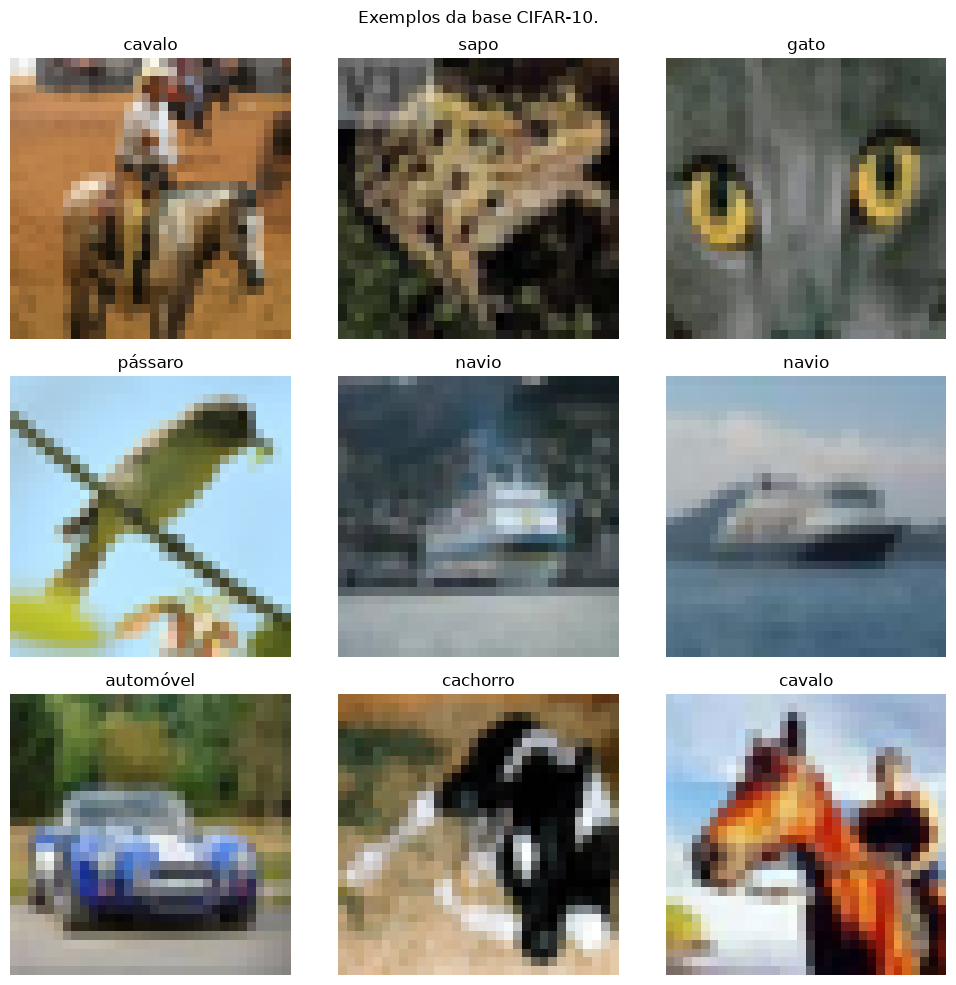

In [4]:
plt.figure(figsize=(10, 10))

for i in range(9):
    num = random.randint(1, 2000)
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[num])
    plt.title(class_names[y_train[num]])

    plt.axis('off')

plt.suptitle('Exemplos da base CIFAR-10.')

plt.tight_layout()

plt.show()

# 4. Criação do CNN

In [21]:
model = keras.Sequential()

# Camada de entrada
model.add(Input(shape=(32, 32, 3)))

# Bloco 1
model.add(Conv2D(
    filters=64,
    kernel_size=(3, 3),
    activation="relu"
))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Bloco 2
model.add(Conv2D(
    filters=128,
    kernel_size=(3, 3),
    activation="relu"
))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Bloco 3
model.add(Conv2D(
    filters=256,
    kernel_size=(3, 3),
    activation="relu"
))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Transição CNN -> Densa
model.add(Flatten())

model.add(Dense(256, activation="relu"))
model.add(Dropout(0.25))

# Saída
model.add(Dense(10, activation="softmax"))

# Compilar
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 30, 30, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 635,786 (2.43 MB)

 Trainable params: 635,786 (2.43 MB)

 Non-trainable params: 0 (0.00 B)

# 5. Treinando a rede 

In [22]:
history = model.fit(X_train, y_train, epochs=8, batch_size=64, validation_split=0.2)

Epoch 1/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.4053 - loss: 1.6102 - val_accuracy: 0.5343 - val_loss: 1.2909
Epoch 2/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.5659 - loss: 1.2195 - val_accuracy: 0.6206 - val_loss: 1.0842
Epoch 3/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.6419 - loss: 1.0233 - val_accuracy: 0.6597 - val_loss: 0.9618
Epoch 4/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.6852 - loss: 0.8998 - val_accuracy: 0.6546 - val_loss: 0.9976
Epoch 5/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.7189 - loss: 0.8034 - val_accuracy: 0.7047 - val_loss: 0.8500
Epoch 6/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.7487 - loss: 0.7204 - val_accuracy: 0.7112 - val_loss: 0.8543
Epoch 7/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.7703 - loss: 0.6529 - val_accuracy: 0.7253 - val_loss: 0.8028
Epoch 8/8
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.7918 - loss: 0.5915 - val_accu

# 6. Plot da acurácia e Loss

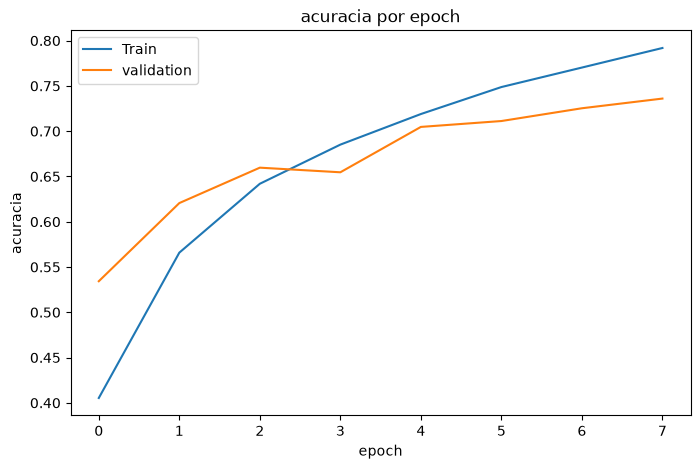

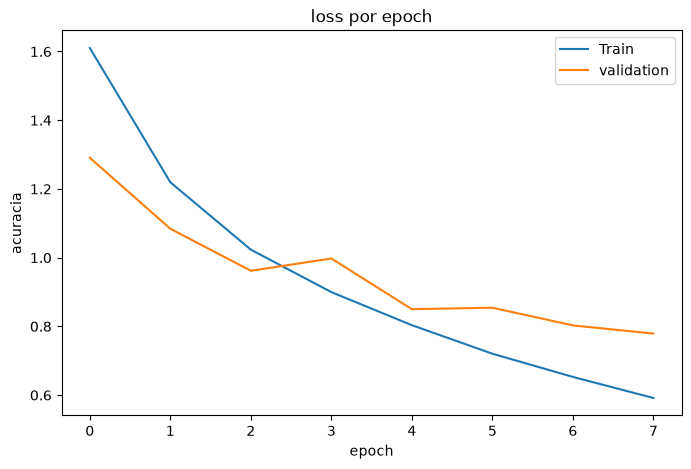

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label="Train")

plt.plot(history.history['val_accuracy'], label="validation")

plt.title('acuracia por epoch')

plt.xlabel('epoch')
plt.ylabel('acuracia')

plt.legend()
plt.show()
######
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label="Train")

plt.plot(history.history['val_loss'], label="validation")

plt.title('loss por epoch')

plt.xlabel('epoch')
plt.ylabel('acuracia')

plt.legend()
plt.show()

# 7. Predições

In [24]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print(f'Acurácia: {test_accuracy * 100:.2f}%\nLoss: {test_loss:.3f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7278 - loss: 0.8078
Acurácia: 72.78%
Loss: 0.808


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


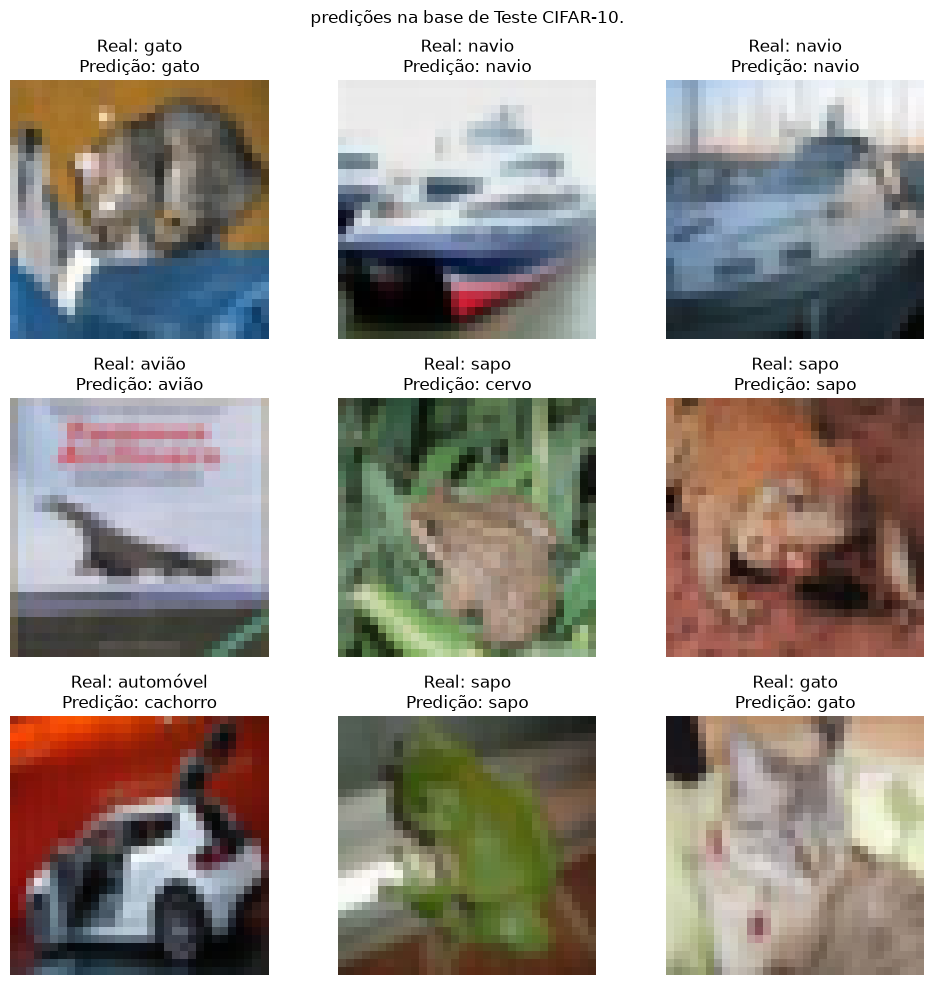

In [25]:
# Previções em imagens do Teste

pred_proba = model.predict(X_test)
y_pred = np.argmax(pred_proba, axis=1)

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    plt.title(class_names[y_train[i]])
    real = class_names[y_test[i]]
    pred = class_names[y_pred[i]]

    plt.title(f"Real: {real}\nPredição: {pred}")
    
    plt.axis('off')

plt.suptitle('predições na base de Teste CIFAR-10.')

plt.tight_layout()

plt.show()

# 8. Matriz de Confusão

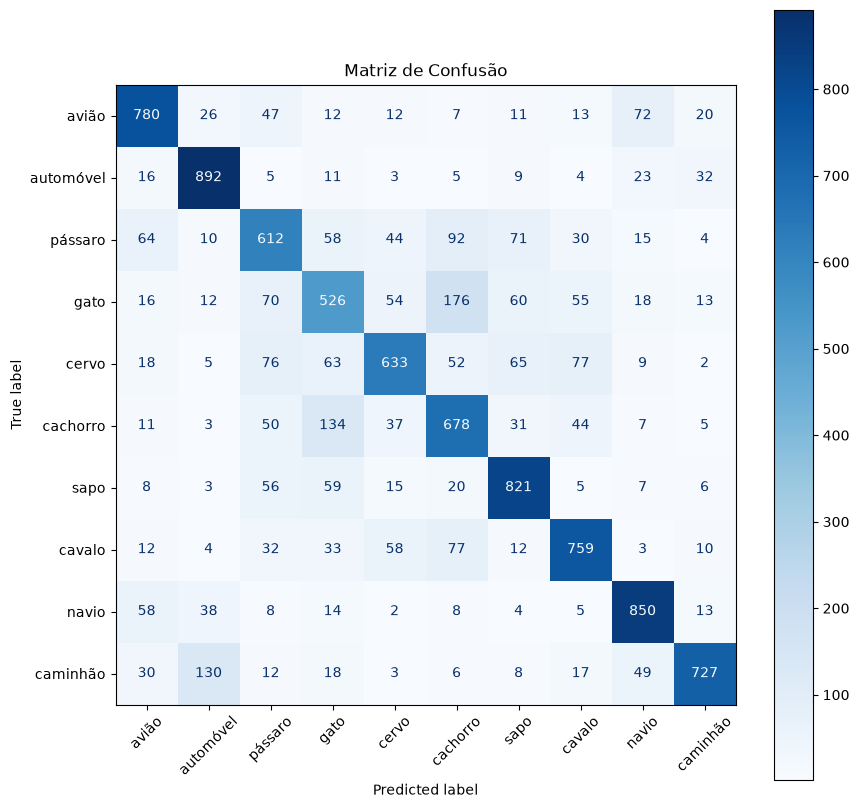

In [26]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Matriz de Confusão")
plt.show()